In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import OLSInfluence

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [115]:
from pathlib import Path

# 1. Configuration
RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = Path("train.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

In [116]:
# 2. Load data and basic audit

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Dataset shape: (1460, 81)
Duplicate rows: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [117]:
# Id is only an identifier and should not be used as a predictor.
df = df.drop(columns=["Id"])

In [118]:
TARGET = "SalePrice"

In [119]:
# -----------------------------
# 3. Missing-value analysis
# -----------------------------
missing_summary = (
    df.isna()
      .sum()
      .to_frame("MissingCount")
)
missing_summary["MissingPercent"] = (
    missing_summary["MissingCount"] / len(df) * 100
)
missing_summary = missing_summary.sort_values(
    "MissingPercent", ascending=False
)

print("\nTop variables by missingness:")
print(missing_summary.head(15))


Top variables by missingness:
              MissingCount  MissingPercent
PoolQC                1453       99.520548
MiscFeature           1406       96.301370
Alley                 1369       93.767123
Fence                 1179       80.753425
MasVnrType             872       59.726027
FireplaceQu            690       47.260274
LotFrontage            259       17.739726
GarageQual              81        5.547945
GarageType              81        5.547945
GarageFinish            81        5.547945
GarageCond              81        5.547945
GarageYrBlt             81        5.547945
BsmtExposure            38        2.602740
BsmtFinType2            38        2.602740
BsmtQual                37        2.534247


In [120]:
missing_summary.to_csv(OUTPUT_DIR / "missing_value_summary.csv")

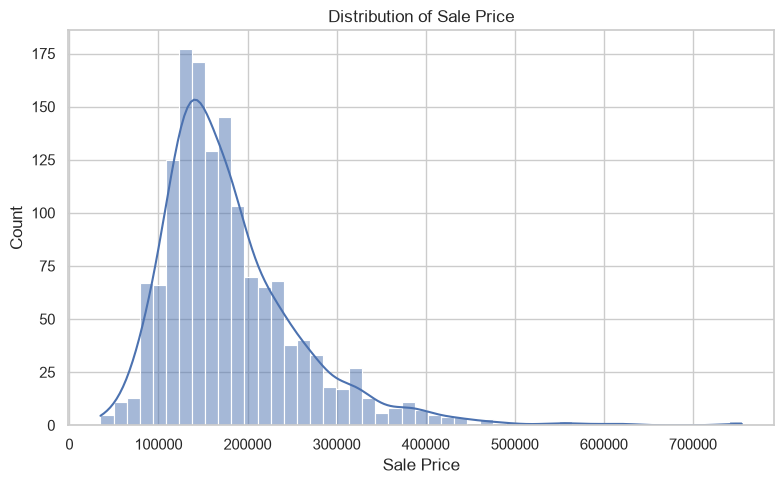

In [121]:
# Important observation:
# In the Ames data, some NA values mean that a feature is absent.
# For example, a missing GarageType usually means that the house has no
# garage, rather than that the garage type was forgotten.
# Therefore, we do NOT simply impute every column in the dataset.


# -----------------------------
# 4. Target distribution
# -----------------------------
plt.figure(figsize=(8, 5))
sns.histplot(df[TARGET], kde=True)
plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_saleprice_distribution.png", dpi=200)
plt.show()

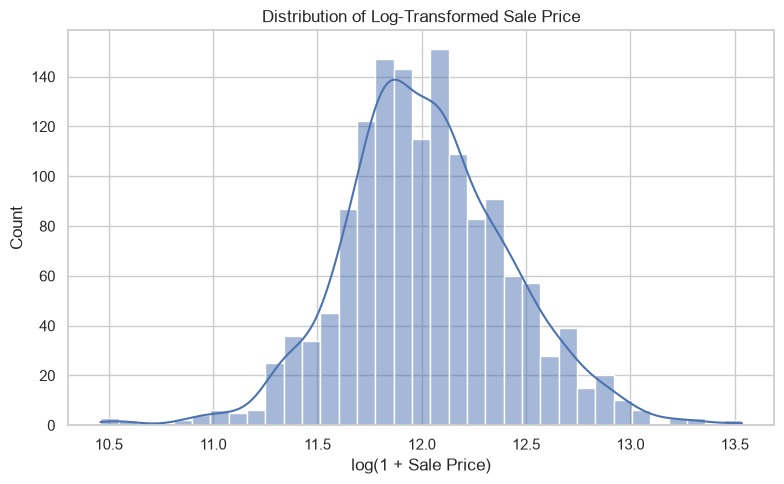

In [122]:
# SalePrice is strongly right-skewed, so use a log transformation.
df["LogSalePrice"] = np.log1p(df[TARGET])

plt.figure(figsize=(8, 5))
sns.histplot(df["LogSalePrice"], kde=True)
plt.title("Distribution of Log-Transformed Sale Price")
plt.xlabel("log(1 + Sale Price)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_log_saleprice_distribution.png", dpi=200)
plt.show()

In [123]:
# -----------------------------
# 5. Domain-driven feature selection
# -----------------------------

# These variables represent size, quality, age, facilities and location.

numeric_features = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "YearRemodAdd",
    "FullBath",
    "Fireplaces",
]

categorical_features = [
    "Neighborhood",
    "KitchenQual",
]

selected_features = numeric_features + categorical_features

model_df = df[selected_features + [TARGET, "LogSalePrice"]].copy()

In [124]:
# -----------------------------
# 6. Train/test split
# -----------------------------
# The split is performed before learning medians, modes or dummy variables.
# This prevents information from the test set leaking into the model.

X = model_df[selected_features].copy()
y = model_df["LogSalePrice"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print("\nTraining observations:", len(X_train))
print("Testing observations :", len(X_test))


Training observations: 1168
Testing observations : 292


In [125]:
# -----------------------------
# 7. Leakage-safe preprocessing
# -----------------------------
# Numeric variables:
#   Missing values -> median learned from training data
#
# Categorical variables:
#   Missing values -> most frequent category
#   Categories -> one-hot encoded
#
# We use a Pipeline so the preprocessing is fitted only on training data.

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

In [126]:
# -----------------------------
# 8. Fit preprocessing on training data
# -----------------------------
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index,
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index,
)

# statsmodels needs an explicit intercept.
X_train_ols = sm.add_constant(X_train_processed, has_constant="add")
X_test_ols = sm.add_constant(X_test_processed, has_constant="add")

In [127]:
# -----------------------------
# 9. Multiple Linear Regression
# -----------------------------
# Model:
#
# log(1 + SalePrice) = beta_0 + beta_1 X_1 + ... + error
#
# We use OLS because it is interpretable and gives us a natural framework
# for statistical inference and regression diagnostics.

ols_model = sm.OLS(y_train, X_train_ols).fit()

print("\n================ OLS SUMMARY ================")
print(ols_model.summary())

# Save the full regression summary as a text file.
with open(OUTPUT_DIR / "ols_summary.txt", "w") as f:
    f.write(ols_model.summary().as_text())


================ OLS SUMMARY ================
                            OLS Regression Results                            
Dep. Variable:           LogSalePrice   R-squared:                       0.854
Model:                            OLS   Adj. R-squared:                  0.850
Method:                 Least Squares   F-statistic:                     189.3
Date:                Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                        01:17:37   Log-Likelihood:                 565.30
No. Observations:                1168   AIC:                            -1059.
Df Residuals:                    1132   BIC:                            -876.3
Df Model:                          35                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

In [128]:
# -----------------------------
# 10. Robust standard errors
# -----------------------------
# House-price data often show non-constant error variance.
# HC3 standard errors provide a more conservative inference framework
# when heteroskedasticity is present.

robust_model = ols_model.get_robustcov_results(cov_type="HC3")

robust_table = pd.DataFrame({
    "Feature": X_train_ols.columns,
    "Coefficient": robust_model.params,
    "Robust_SE": robust_model.bse,
    "t_value": robust_model.tvalues,
    "p_value": robust_model.pvalues,
    "CI_Lower": robust_model.conf_int()[:, 0],
    "CI_Upper": robust_model.conf_int()[:, 1],
})

robust_table.to_csv(OUTPUT_DIR / "robust_regression_coefficients.csv", index=False)

In [129]:
# -----------------------------
# 11. Multicollinearity: VIF
# -----------------------------
# VIF is calculated for the numeric explanatory variables used in the model.
# A very high VIF suggests that coefficients may be unstable because the
# variable overlaps strongly with other predictors.

vif_input = X_train[numeric_features].copy()
vif_input = vif_input.fillna(vif_input.median())

vif_table = pd.DataFrame({
    "Feature": vif_input.columns,
    "VIF": [
        variance_inflation_factor(vif_input.values, i)
        for i in range(vif_input.shape[1])
    ],
})

vif_table = vif_table.sort_values("VIF", ascending=False)
vif_table.to_csv(OUTPUT_DIR / "vif_table.csv", index=False)

print("\nVIF table:")
print(vif_table)


VIF table:
        Feature          VIF
4     YearBuilt  7931.851995
5  YearRemodAdd  7742.694144
0   OverallQual    46.939091
1     GrLivArea    23.267995
6      FullBath    17.885077
3    GarageCars    11.860086
2   TotalBsmtSF    10.609385
7    Fireplaces     2.576062


In [130]:
# -----------------------------
# 12. Predictions and model metrics
# -----------------------------
y_train_pred_log = ols_model.predict(X_train_ols)
y_test_pred_log = ols_model.predict(X_test_ols)

# Convert predictions back to the original price scale.
y_test_actual = np.expm1(y_test)
y_test_pred = np.expm1(y_test_pred_log)

mae = mean_absolute_error(y_test_actual, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_test_pred))
r2 = r2_score(y_test_actual, y_test_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2],
})

print("\n================ TEST PERFORMANCE ================")
print(metrics)
metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)


================ TEST PERFORMANCE ================
  Metric         Value
0    MAE  18488.755417
1   RMSE  28443.616250
2     R2      0.894523


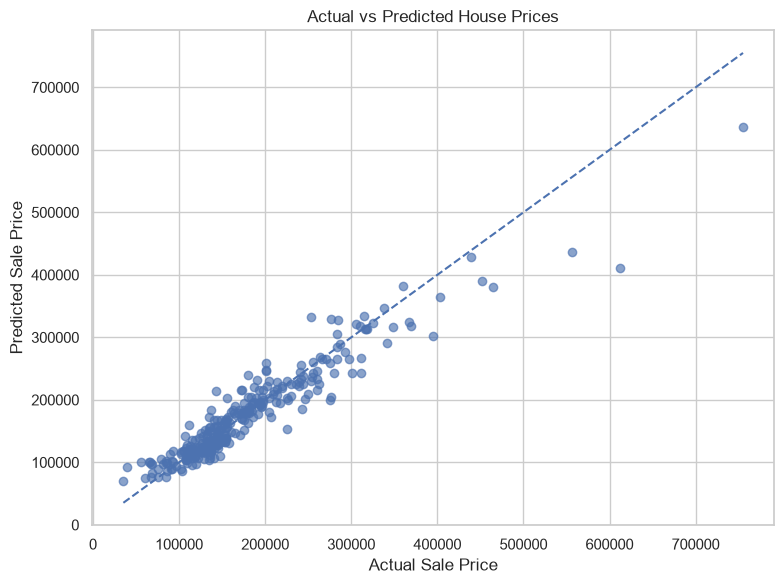

In [131]:
# -----------------------------
# 13. Actual vs predicted prices
# -----------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, y_test_pred, alpha=0.65)

line_min = min(y_test_actual.min(), y_test_pred.min())
line_max = max(y_test_actual.max(), y_test_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_actual_vs_predicted.png", dpi=200)
plt.show()

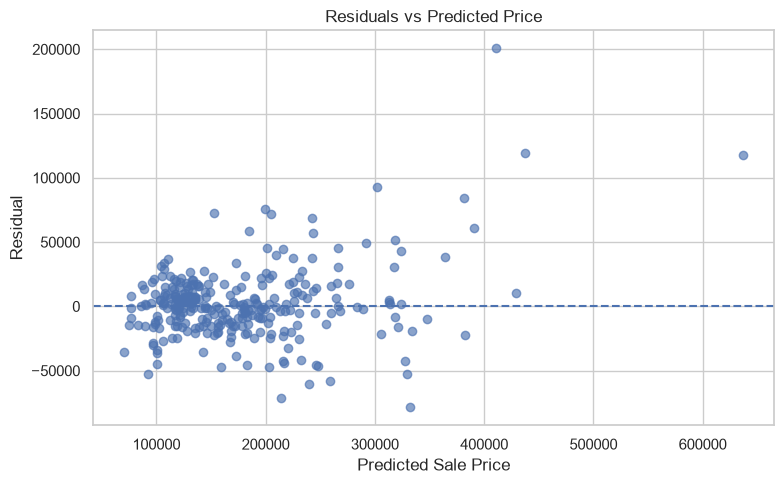

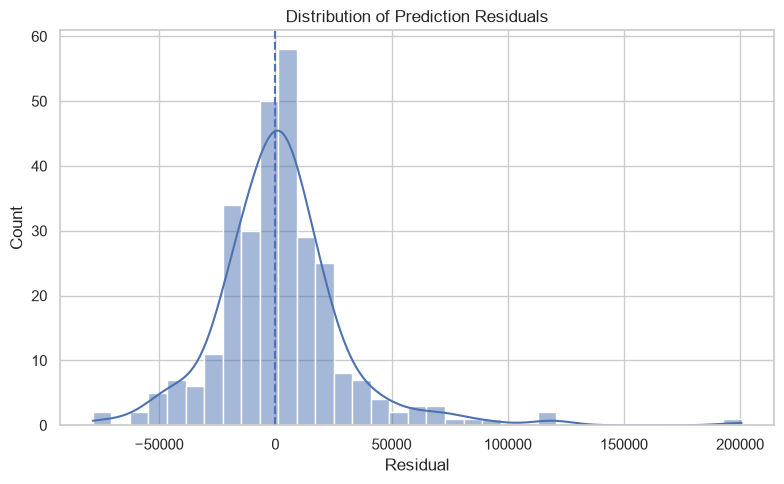

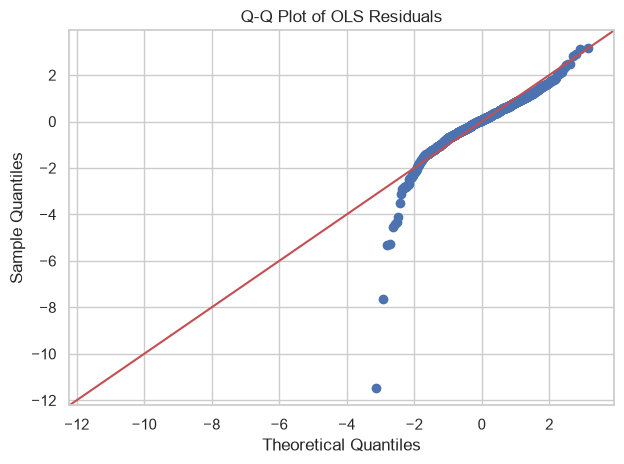

In [132]:
# -----------------------------
# 14. Residual diagnostics
# -----------------------------
residuals = y_test_actual - y_test_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_residual_plot.png", dpi=200)
plt.show()


plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual")
plt.title("Distribution of Prediction Residuals")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_residual_distribution.png", dpi=200)
plt.show()


# Q-Q plot is more informative for normality than a histogram alone.
sm.qqplot(ols_model.resid, line="45", fit=True)
plt.title("Q-Q Plot of OLS Residuals")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_qq_plot.png", dpi=200)
plt.show()

In [133]:
# -----------------------------
# 15. Formal regression diagnostics
# -----------------------------
# Breusch-Pagan test checks for heteroskedasticity.
bp_lm, bp_lm_pvalue, bp_fvalue, bp_f_pvalue = het_breuschpagan(
    ols_model.resid,
    ols_model.model.exog,
)

# Jarque-Bera checks skewness and kurtosis of residuals.
jb_stat, jb_pvalue, skewness, kurtosis = jarque_bera(ols_model.resid)

# Cook's distance identifies observations that have unusually high influence
# on the fitted regression coefficients.
influence = OLSInfluence(ols_model)
cooks_d = influence.cooks_distance[0]

cook_threshold = 4 / len(X_train)
influential_points = pd.DataFrame({
    "Index": X_train.index,
    "CooksDistance": cooks_d,
})
influential_points = influential_points[
    influential_points["CooksDistance"] > cook_threshold
].sort_values("CooksDistance", ascending=False)

influential_points.to_csv(
    OUTPUT_DIR / "influential_observations.csv",
    index=False,
)

print("\n================ REGRESSION DIAGNOSTICS ================")
print(f"Breusch-Pagan p-value: {bp_f_pvalue:.6f}")
print(f"Jarque-Bera p-value   : {jb_pvalue:.6f}")
print(f"Cook's D threshold    : {cook_threshold:.6f}")
print(f"Potentially influential observations: {len(influential_points)}")


================ REGRESSION DIAGNOSTICS ================
Breusch-Pagan p-value: 0.000000
Jarque-Bera p-value   : 0.000000
Cook's D threshold    : 0.003425
Potentially influential observations: 55


In [134]:
# -----------------------------
# 16. Business Output 1: key price drivers
# -----------------------------
# For a log-linear model, a coefficient beta can be approximately interpreted
# as a percentage change in price for a one-unit increase in the predictor,
# holding other included variables constant.
#
# For larger changes, the exact multiplicative interpretation is:
#   percentage effect = (exp(beta * change) - 1) * 100
#
# We create a clean table for the most important interpretable variables.

business_features = [
    "numeric__OverallQual",
    "numeric__GrLivArea",
    "numeric__TotalBsmtSF",
    "numeric__GarageCars",
    "numeric__YearBuilt",
    "numeric__YearRemodAdd",
    "numeric__FullBath",
    "numeric__Fireplaces",
]

business_rows = []

for feature in business_features:
    if feature in robust_table["Feature"].values:
        row = robust_table.loc[
            robust_table["Feature"] == feature
        ].iloc[0]

        clean_name = feature.replace("numeric__", "")
        beta = row["Coefficient"]

        business_rows.append({
            "Feature": clean_name,
            "Coefficient": beta,
            "Approx_Pct_Change_Per_Unit": (np.exp(beta) - 1) * 100,
            "P_Value": row["p_value"],
        })

business_driver_table = pd.DataFrame(business_rows)
business_driver_table["AbsoluteEffect"] = business_driver_table[
    "Approx_Pct_Change_Per_Unit"
].abs()
business_driver_table = business_driver_table.sort_values(
    "AbsoluteEffect", ascending=False
).drop(columns="AbsoluteEffect")

business_driver_table.to_csv(
    OUTPUT_DIR / "business_price_drivers.csv",
    index=False,
)

print("\n================ KEY PRICE DRIVERS ================")
print(business_driver_table)


================ KEY PRICE DRIVERS ================
        Feature  Coefficient  Approx_Pct_Change_Per_Unit       P_Value
3    GarageCars     0.077600                    8.068997  1.474778e-06
0   OverallQual     0.069339                    7.180001  1.306686e-15
7    Fireplaces     0.059124                    6.090705  1.382490e-10
6      FullBath     0.002411                    0.241368  9.281611e-01
5  YearRemodAdd     0.002097                    0.209918  6.563152e-10
4     YearBuilt     0.001444                    0.144548  1.427217e-02
1     GrLivArea     0.000193                    0.019285  1.613283e-04
2   TotalBsmtSF     0.000069                    0.006899  2.534079e-01


In [135]:
# -----------------------------
# 17. Business Output 2: neighborhood benchmark
# -----------------------------
# This is descriptive, not causal. It tells us which neighborhoods have
# higher/lower observed prices in this sample.

neighborhood_summary = (
    df.groupby("Neighborhood")[TARGET]
      .agg(["count", "median", "mean"])
      .sort_values("median", ascending=False)
)

neighborhood_summary.to_csv(
    OUTPUT_DIR / "neighborhood_price_benchmark.csv"
)

print("\n================ NEIGHBORHOOD PRICE BENCHMARK ================")
print(neighborhood_summary.head(10))


================ NEIGHBORHOOD PRICE BENCHMARK ================
              count    median           mean
Neighborhood                                
NridgHt          77  315000.0  316270.623377
NoRidge          41  301500.0  335295.317073
StoneBr          25  278000.0  310499.000000
Timber           38  228475.0  242247.447368
Somerst          86  225500.0  225379.837209
Veenker          11  218000.0  238772.727273
Crawfor          51  200624.0  210624.725490
ClearCr          28  200250.0  212565.428571
CollgCr         150  197200.0  197965.773333
Blmngtn          17  191000.0  194870.882353


In [136]:
# -----------------------------
# 18. Business Output 3: model-based pricing gap
# -----------------------------
# A positive residual means the actual sale price was above the model's
# predicted price; a negative residual means it was below the prediction.
# This should be treated as a valuation/benchmarking signal, NOT proof that
# a property was objectively over- or under-valued.

pricing_gap = X_test.copy()
pricing_gap["ActualPrice"] = y_test_actual
pricing_gap["PredictedPrice"] = y_test_pred
pricing_gap["PricingGap"] = (
    pricing_gap["ActualPrice"] - pricing_gap["PredictedPrice"]
)
pricing_gap["GapPercent"] = (
    pricing_gap["PricingGap"] / pricing_gap["PredictedPrice"] * 100
)

pricing_gap = pricing_gap.sort_values("GapPercent", ascending=False)

pricing_gap.head(20).to_csv(
    OUTPUT_DIR / "largest_positive_pricing_gaps.csv",
    index=False,
)

pricing_gap.tail(20).to_csv(
    OUTPUT_DIR / "largest_negative_pricing_gaps.csv",
    index=False,
)

In [137]:
# -----------------------------
# 19. Business Output 4: simple scenario analysis
# -----------------------------
# We illustrate how the fitted model can be used as a decision-support tool.
# We do NOT call this a causal estimate. It is a model-based scenario.
#
# Example question:
# "For a representative house, how does the predicted price change if
# OverallQual increases by one point?"

# Use the median numeric profile and the most common categorical profile.
representative = {}

for col in numeric_features:
    representative[col] = X_train[col].median()

for col in categorical_features:
    representative[col] = X_train[col].mode(dropna=True).iloc[0]

representative_df = pd.DataFrame([representative])

base_processed = preprocessor.transform(representative_df)
base_processed = pd.DataFrame(
    base_processed,
    columns=feature_names,
)
base_processed = sm.add_constant(base_processed, has_constant="add")

base_log_price = float(ols_model.predict(base_processed).iloc[0])
base_price = float(np.expm1(base_log_price))

scenario_df = representative_df.copy()
scenario_df["OverallQual"] = scenario_df["OverallQual"] + 1

scenario_processed = preprocessor.transform(scenario_df)
scenario_processed = pd.DataFrame(
    scenario_processed,
    columns=feature_names,
)
scenario_processed = sm.add_constant(scenario_processed, has_constant="add")

scenario_log_price = float(ols_model.predict(scenario_processed).iloc[0])
scenario_price = float(np.expm1(scenario_log_price))

scenario_output = pd.DataFrame({
    "Scenario": [
        "Representative house",
        "Same house with OverallQual increased by 1 point",
    ],
    "PredictedPrice": [base_price, scenario_price],
})

scenario_output["Change"] = scenario_output["PredictedPrice"] - base_price
scenario_output["PercentChange"] = (
    scenario_output["Change"] / base_price * 100
)

scenario_output.to_csv(
    OUTPUT_DIR / "quality_scenario_analysis.csv",
    index=False,
)

print("\n================ SCENARIO ANALYSIS ================")
print(scenario_output)


================ SCENARIO ANALYSIS ================
                                           Scenario  PredictedPrice  \
0                              Representative house   173551.036245   
1  Same house with OverallQual increased by 1 point   186012.074237   

         Change  PercentChange  
0      0.000000       0.000000  
1  12461.037992       7.180042  


In [138]:

# -----------------------------
# 20. Final project summary
# -----------------------------
print("\n============================================================")
print("PROJECT COMPLETE")
print("============================================================")
print("Main model: Multiple Linear Regression on log(1 + SalePrice)")
print(f"Test MAE : {mae:,.0f}")
print(f"Test RMSE: {rmse:,.0f}")
print(f"Test R2  : {r2:.3f}")
print("\nOutputs saved to:", OUTPUT_DIR.resolve())



PROJECT COMPLETE
Main model: Multiple Linear Regression on log(1 + SalePrice)
Test MAE : 18,489
Test RMSE: 28,444
Test R2  : 0.895

Outputs saved to: C:\Users\Lenovo\House-Price-Prediction\outputs
